### Objective: Understand how Sales and Profit change over time and identify business trends.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/ecommerce_sales_data.csv")
df.head()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
0,2024-12-31,Printer,Office,North,4,3640,348.93
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73
3,2024-03-16,Mouse,Accessories,South,2,786,202.87
4,2022-09-10,Mouse,Accessories,West,1,509,103.28


In [23]:
# Replace spaces with underscores in all column names
df.columns = df.columns.str.replace(' ', '_')

# Check column names
print(df.columns.tolist())

['Order_Date', 'Product_Name', 'Category', 'Region', 'Quantity', 'Sales', 'Profit']


In [24]:
# Convert Order Date into datetime format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Extract date information
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%B')
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)
df['Year_Month'] = df['Order_Date'].dt.strftime('%Y-%m')

# Display the updated dataset
df.head()

,Order_Date,Product_Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
0,2024-12-31,Printer,Office,North,4,3640,348.93,2024,12,December,Q4,2024-12
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53,2022,11,November,Q4,2022-11
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73,2022,5,May,Q2,2022-05
3,2024-03-16,Mouse,Accessories,South,2,786,202.87,2024,3,March,Q1,2024-03
4,2022-09-10,Mouse,Accessories,West,1,509,103.28,2022,9,September,Q3,2022-09


In [25]:
required_columns = [
    'Order_Date',
    'Product_Name',
    'Category',
    'Region',
    'Quantity',
    'Sales',
    'Profit',
    'Year',
    'Month',
    'Month_Name',
    'Quarter',
    'Year_Month'
]

df = df[required_columns]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3500, 12)


,Order_Date,Product_Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
0,2024-12-31,Printer,Office,North,4,3640,348.93,2024,12,December,Q4,2024-12
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53,2022,11,November,Q4,2022-11
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73,2022,5,May,Q2,2022-05
3,2024-03-16,Mouse,Accessories,South,2,786,202.87,2024,3,March,Q1,2024-03
4,2022-09-10,Mouse,Accessories,West,1,509,103.28,2022,9,September,Q3,2022-09


In [26]:
df.to_csv(
    "../data/processed/ecommerce_processed_dataset.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [28]:
df = pd.read_csv("../data/processed/ecommerce_processed_dataset.csv")
df.head()

,Order_Date,Product_Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
0,2024-12-31,Printer,Office,North,4,3640,348.93,2024,12,December,Q4,2024-12
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53,2022,11,November,Q4,2022-11
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73,2022,5,May,Q2,2022-05
3,2024-03-16,Mouse,Accessories,South,2,786,202.87,2024,3,March,Q1,2024-03
4,2022-09-10,Mouse,Accessories,West,1,509,103.28,2022,9,September,Q3,2022-09


### 1.Monthly Sales Trend Analysis

In [35]:
# Group sales by Year_Month
monthly_sales = df.groupby('Year_Month')['Sales'].sum().reset_index()

# Sort months chronologically
monthly_sales = monthly_sales.sort_values('Year_Month')



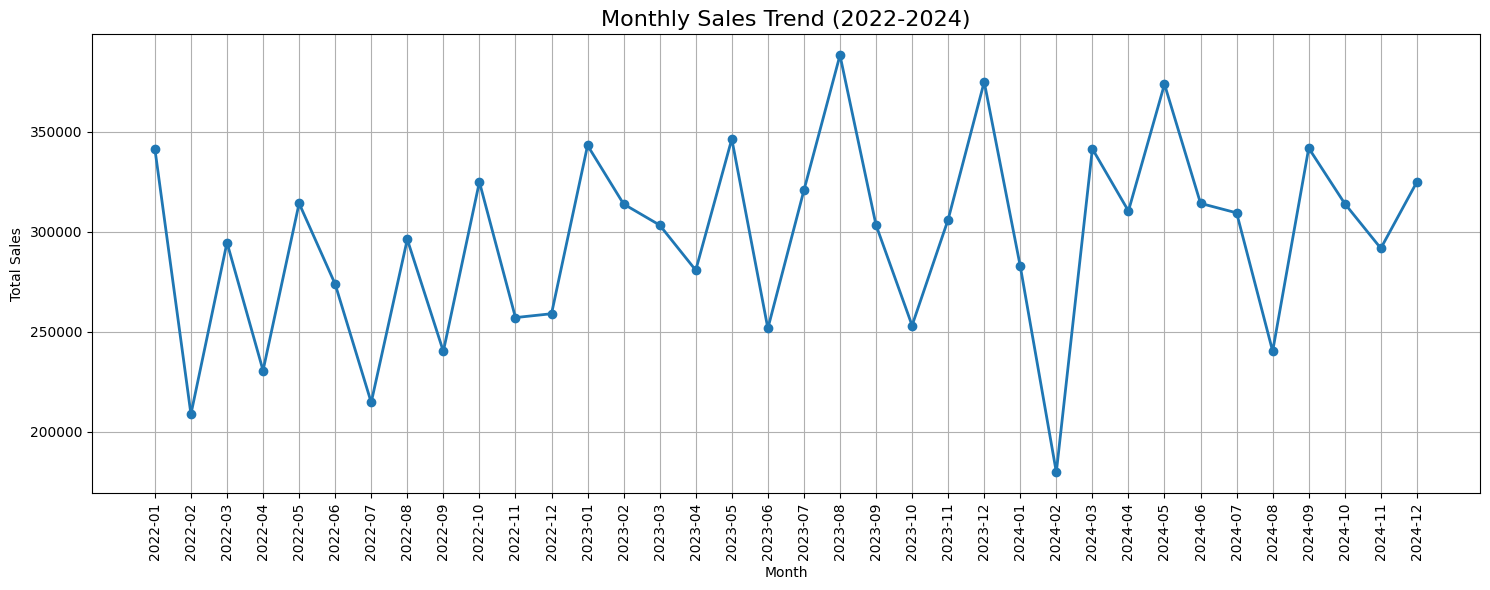

In [31]:
# Create monthly sales trend chart

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales['Year_Month'],
    monthly_sales['Sales'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend (2022-2024)', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

#### Identify Highest and Lowest Sales Months

In [ ]:
highest_sales_month = monthly_sales.loc[monthly_sales['Sales'].idxmax()]
lowest_sales_month = monthly_sales.loc[monthly_sales['Sales'].idxmin()]

print("Highest Sales Month:")
print(highest_sales_month)

print("\nLowest Sales Month:")
print(lowest_sales_month)

Highest Sales Month:
Year_Month    2023-08
Sales          388428
Name: 19, dtype: object

Lowest Sales Month:
Year_Month    2024-02
Sales          179708
Name: 25, dtype: object


### 2. Monthly Profit Trend Analysis

In [36]:
# Calculate Monthly Profit
monthly_profit = df.groupby('Year_Month')['Profit'].sum().reset_index()

monthly_profit = monthly_profit.sort_values('Year_Month')

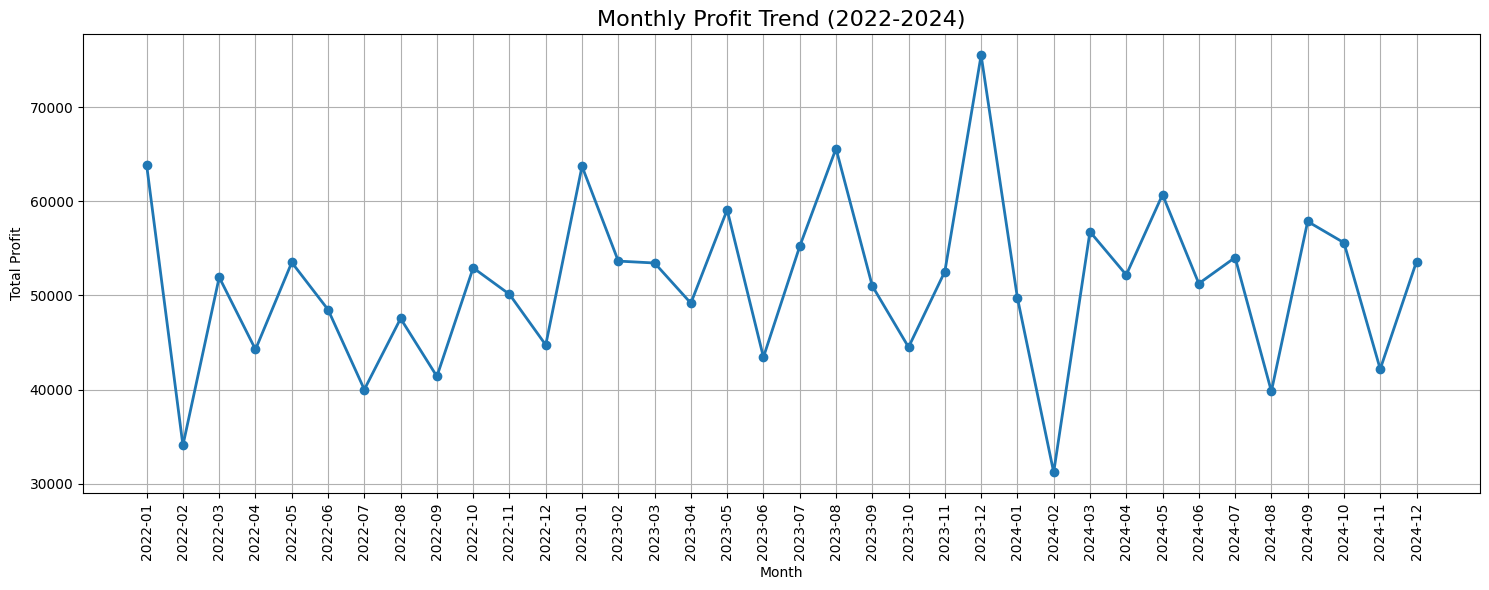

In [34]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_profit['Year_Month'],
    monthly_profit['Profit'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Profit Trend (2022-2024)', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Profit')

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

#### Identify Highest and Lowest Profit Months

In [37]:
highest_profit_month = monthly_profit.loc[monthly_profit['Profit'].idxmax()]
lowest_profit_month = monthly_profit.loc[monthly_profit['Profit'].idxmin()]

print("Highest Profit Month:")
print(highest_profit_month)

print("\nLowest Profit Month:")
print(lowest_profit_month)

Highest Profit Month:
Year_Month     2023-12
Profit        75505.76
Name: 23, dtype: object

Lowest Profit Month:
Year_Month     2024-02
Profit        31228.39
Name: 25, dtype: object


### 3. Yearly Sales and Profit Analysis
Which year performed better in terms of Sales and Profit?

In [39]:
# Calculate Yearly Performance
yearly_performance = df.groupby('Year').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Transactions=('Order_Date', 'count')
).reset_index()

yearly_performance['Profit_Margin_%'] = (
    yearly_performance['Total_Profit'] /
    yearly_performance['Total_Sales']
) * 100
yearly_performance

,Year,Total_Sales,Total_Profit,Total_Quantity,Total_Transactions,Profit_Margin_%
0,2022,3255970,572856.98,5387,1094,17.594050
1,2023,3786592,666866.42,5925,1204,17.611256
2,2024,3625319,604941.81,5949,1202,16.686582


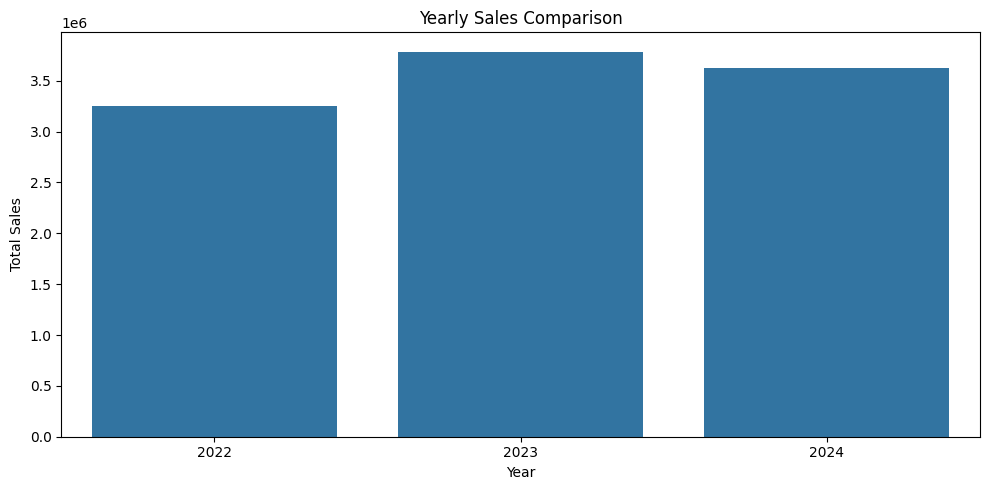

In [42]:
# Yearly Sales Comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_performance,
    x='Year',
    y='Total_Sales'
)

plt.title('Yearly Sales Comparison')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

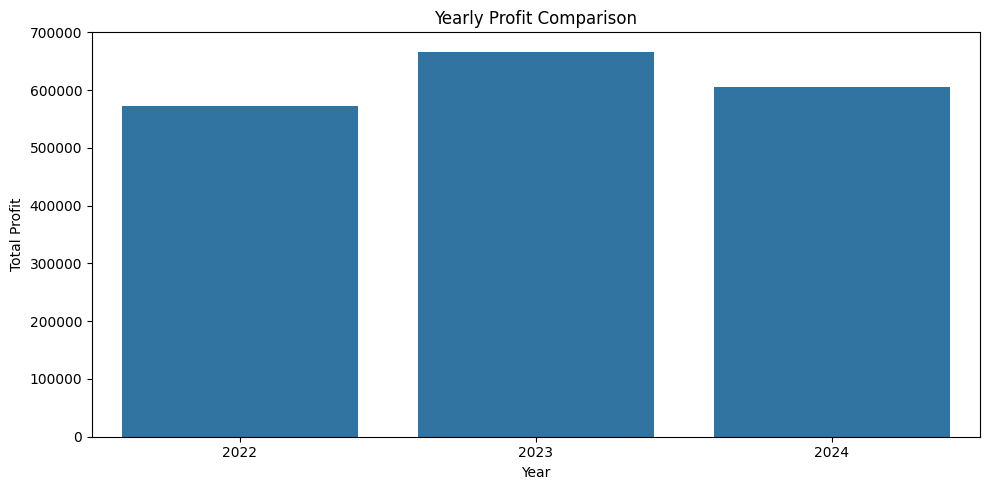

In [44]:
# Yearly Profit Comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_performance,
    x='Year',
    y='Total_Profit'
)

plt.title('Yearly Profit Comparison')
plt.xlabel('Year')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.show()

In [45]:
# Identify Best Performing Year
best_sales_year = yearly_performance.loc[
    yearly_performance['Total_Sales'].idxmax()
]

best_profit_year = yearly_performance.loc[
    yearly_performance['Total_Profit'].idxmax()
]

print("Best Sales Year:")
print(best_sales_year)

print("\nBest Profit Year:")
print(best_profit_year)

Best Sales Year:
Year                  2.023000e+03
Total_Sales           3.786592e+06
Total_Profit          6.668664e+05
Total_Quantity        5.925000e+03
Total_Transactions    1.204000e+03
Profit_Margin_%       1.761126e+01
Name: 1, dtype: float64

Best Profit Year:
Year                  2.023000e+03
Total_Sales           3.786592e+06
Total_Profit          6.668664e+05
Total_Quantity        5.925000e+03
Total_Transactions    1.204000e+03
Profit_Margin_%       1.761126e+01
Name: 1, dtype: float64


### 4. Quarterly Sales and Profit Analysis
Which quarter generates the highest Sales and Profit?

In [46]:
# Calculate Quarterly Performance
quarterly_performance = df.groupby(['Year', 'Quarter']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

quarterly_performance['Profit_Margin_%'] = (
    quarterly_performance['Total_Profit'] /
    quarterly_performance['Total_Sales']
) * 100

display(quarterly_performance.round(2))

,Year,Quarter,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
0,2022,Q1,844979,149844.04,1384,17.73
1,2022,Q2,818770,146256.35,1373,17.86
2,2022,Q3,751080,128965.08,1265,17.17
3,2022,Q4,841141,147791.51,1365,17.57
4,2023,Q1,960578,170796.88,1498,17.78
5,2023,Q2,878975,151712.15,1426,17.26
6,2023,Q3,1012635,171808.51,1553,16.97
7,2023,Q4,934404,172548.88,1448,18.47
8,2024,Q1,804085,137734.72,1295,17.13
9,2024,Q2,998623,164144.14,1634,16.44


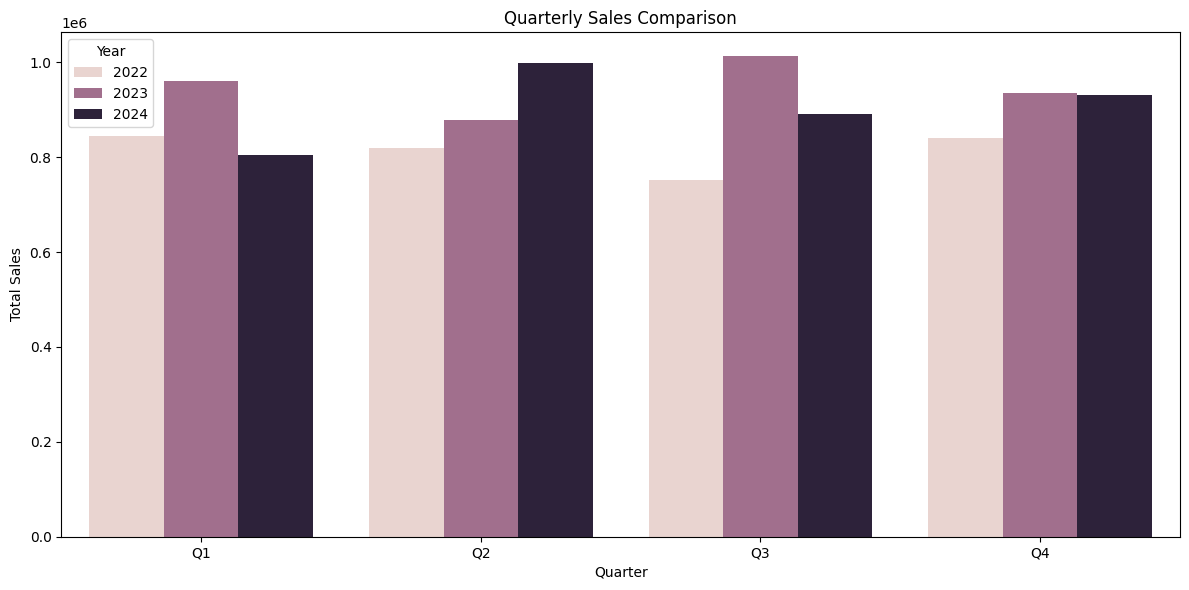

In [47]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=quarterly_performance,
    x='Quarter',
    y='Total_Sales',
    hue='Year'
)

plt.title('Quarterly Sales Comparison')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

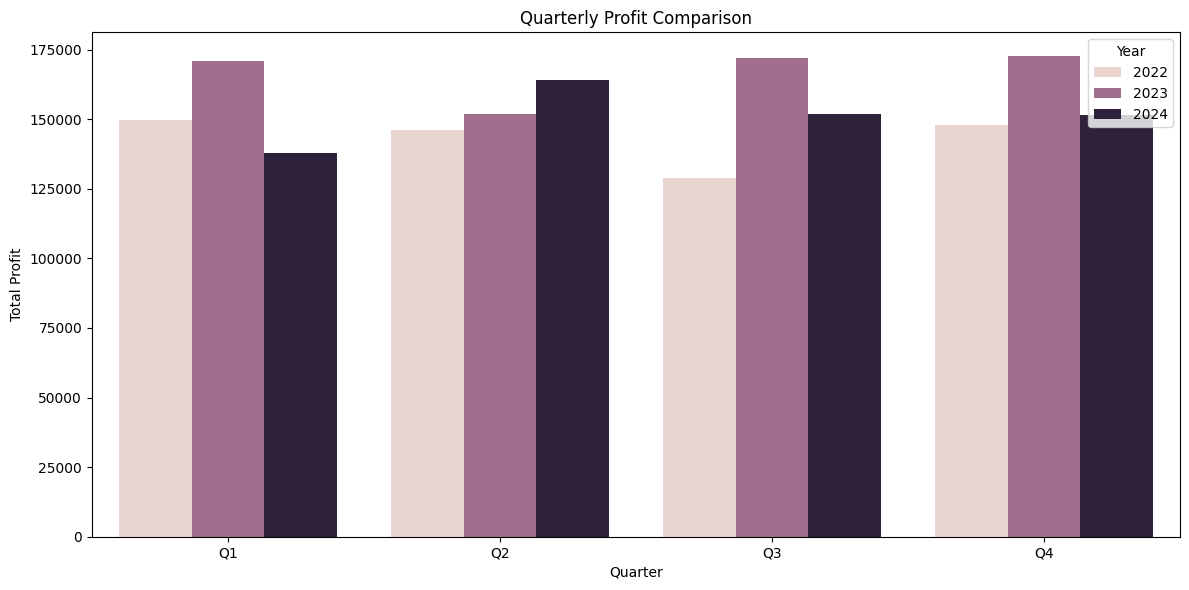

In [48]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=quarterly_performance,
    x='Quarter',
    y='Total_Profit',
    hue='Year'
)

plt.title('Quarterly Profit Comparison')
plt.xlabel('Quarter')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.show()

### 5. Monthly Seasonal Pattern Analysis

In [49]:
monthly_seasonality = df.groupby('Month_Name').agg(
    Average_Sales=('Sales', 'sum')
).reset_index()

# Calculate monthly average across the three years
monthly_seasonality['Average_Sales'] = (
    monthly_seasonality['Average_Sales'] / 3
)

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_seasonality['Month_Name'] = pd.Categorical(
    monthly_seasonality['Month_Name'],
    categories=month_order,
    ordered=True
)

monthly_seasonality = monthly_seasonality.sort_values('Month_Name')

display(monthly_seasonality.round(2))

,Month_Name,Average_Sales
4,January,322538.00
3,February,234138.00
7,March,313204.67
0,April,273958.67
8,May,344895.67
6,June,279935.00
5,July,281646.67
1,August,308313.00
11,September,295182.00
10,October,297423.00


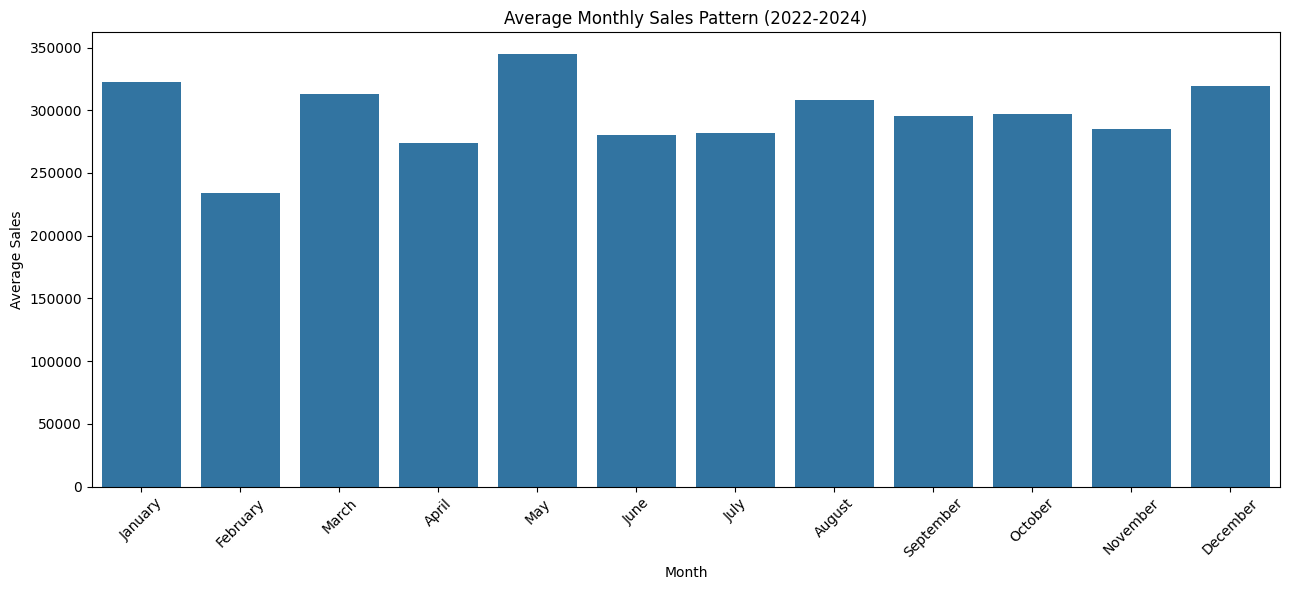

In [50]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=monthly_seasonality,
    x='Month_Name',
    y='Average_Sales'
)

plt.title('Average Monthly Sales Pattern (2022-2024)')
plt.xlabel('Month')
plt.ylabel('Average Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6. Sales Growth Analysis
How much did Sales grow or decline compared with the previous year?

In [51]:
yearly_performance['Sales_Growth_%'] = (
    yearly_performance['Total_Sales'].pct_change() * 100
)

yearly_performance['Profit_Growth_%'] = (
    yearly_performance['Total_Profit'].pct_change() * 100
)

display(
    yearly_performance[
        ['Year', 'Sales_Growth_%', 'Profit_Growth_%']
    ].round(2)
)

,Year,Sales_Growth_%,Profit_Growth_%
0,2022,NaN,NaN
1,2023,16.30,16.41
2,2024,-4.26,-9.29


### 7. Sales vs Profit Trend Comparison
Are Sales and Profit moving in the same direction?

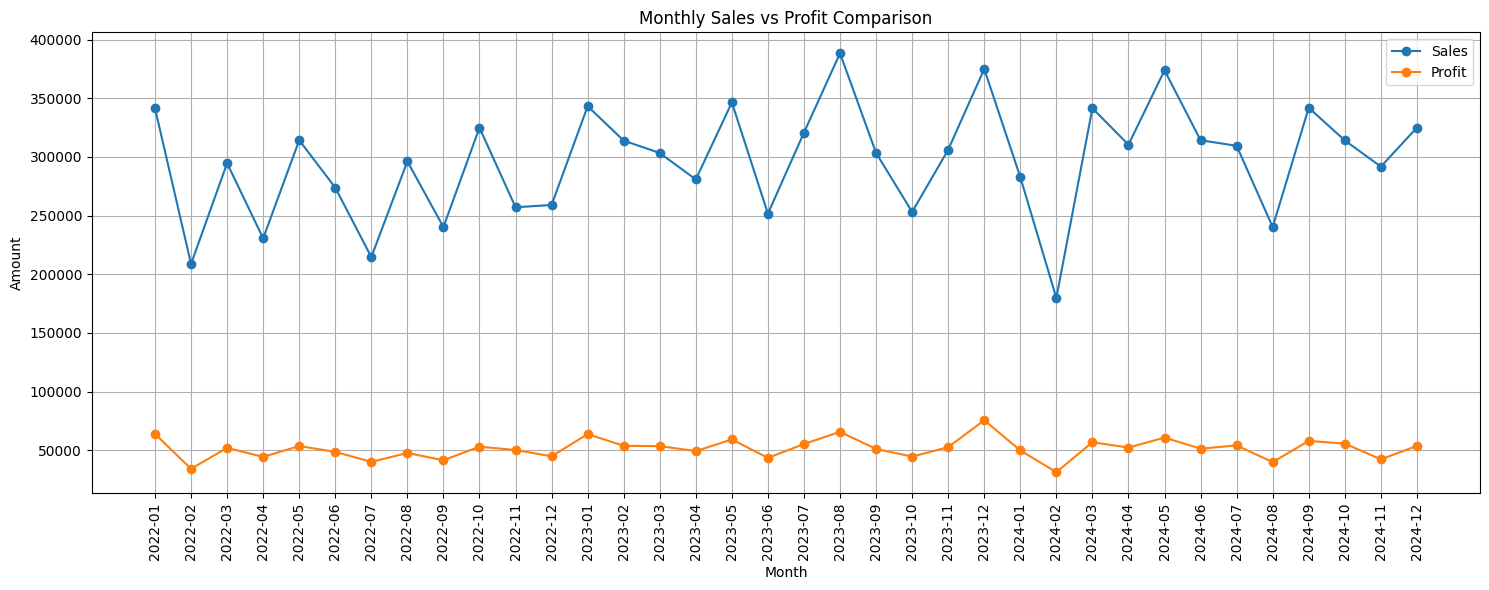

In [52]:
monthly_comparison = df.groupby('Year_Month').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_comparison['Year_Month'],
    monthly_comparison['Total_Sales'],
    label='Sales',
    marker='o'
)

plt.plot(
    monthly_comparison['Year_Month'],
    monthly_comparison['Total_Profit'],
    label='Profit',
    marker='o'
)

plt.title('Monthly Sales vs Profit Comparison')
plt.xlabel('Month')
plt.ylabel('Amount')

plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 8. Final Sales Trend Analysis Summary

In [54]:
print("========== SALES TREND ANALYSIS SUMMARY ==========")

print(f"\nTotal Sales: ₹{df['Sales'].sum():,.2f}")
print(f"Total Profit: ₹{df['Profit'].sum():,.2f}")

print(f"\nHighest Sales Month: {highest_sales_month['Year_Month']}")
print(f"Highest Monthly Sales: ₹{highest_sales_month['Sales']:,.2f}")

print(f"\nLowest Sales Month: {lowest_sales_month['Year_Month']}")
print(f"Lowest Monthly Sales: ₹{lowest_sales_month['Sales']:,.2f}")

print(f"\nHighest Profit Month: {highest_profit_month['Year_Month']}")
print(f"Highest Monthly Profit: ₹{highest_profit_month['Profit']:,.2f}")

print(f"\nLowest Profit Month: {lowest_profit_month['Year_Month']}")
print(f"Lowest Monthly Profit: ₹{lowest_profit_month['Profit']:,.2f}")

print("\nBest Sales Year:", best_sales_year['Year'])
print("Best Profit Year:", best_profit_year['Year'])


========== SALES TREND ANALYSIS SUMMARY ==========

Total Sales: ₹10,667,881.00
Total Profit: ₹1,844,665.21

Highest Sales Month: 2023-08
Highest Monthly Sales: ₹388,428.00

Lowest Sales Month: 2024-02
Lowest Monthly Sales: ₹179,708.00

Highest Profit Month: 2023-12
Highest Monthly Profit: ₹75,505.76

Lowest Profit Month: 2024-02
Lowest Monthly Profit: ₹31,228.39

Best Sales Year: 2023.0
Best Profit Year: 2023.0
